# UPI Spending Analysis

## Project Overview

This project analyses six months of personal UPI transaction data from January to June 2026 extracted from a Google Pay transaction statement

The workflow covers PDF- based transaction extraction, data cleaning, feature engineering, transaction categorisation and exploratory data analysis.

### Tools
Python · Pandas · Matplotlib · pdfplumber

### Analytical Focus
- Spending trends over time
- Category and merchant- level expenditure
- Transaction behaviour 
- Paid vs Received money flow
- Spending concentration
- Data quality and categorisation challenges

## Objectives

- Compare money paid and received
- Analyse monthly spending patterns
- Identify major spending categories
- Identify top merchants by total spending
- Analyse transaction frequency and average transaction value
- Analyse weekday vs weekend spending
- Examine spending concentration across merchants/categories
- Identify top 10% concentration analysis


1. IMPORT LIBRARIES

In [2]:
import pdfplumber
import pandas as pd
import re
import matplotlib.pyplot as plt

2. DATA EXTRACTION

In [3]:
pdf_path="/home/paragchengappa/programming/UPI-Spending-Analyser/data/raw/bankstats.pdf"

text=""

with pdfplumber.open(pdf_path) as pdf:
    for page in pdf.pages:
        page_text=page.extract_text()
        if page_text:
            text+=page_text+"\n"

print(text[:3000])

Transaction statement
9019517497, paragchengappa@gmail.com
Transactionstatementperiod Sent Received
01January2026-30June2026 ₹77,368.99 ₹70,536
Date&time Transactiondetails Amount
03Jan,2026 PaidtoJAYARAMAPB ₹30
07:41AM UPITransactionID:600358945338
PaidbyStateBankofIndia7202
03Jan,2026 PaidtoSHIVANNA SHIVANNA ₹231
02:17PM UPITransactionID:636962750553
PaidbyStateBankofIndia7202
05Jan,2026 PaidtoPARASHURAMA ₹56.15
07:29AM UPITransactionID:600553332781
PaidbyStateBankofIndia7202
05Jan,2026 PaidtoRAMESHMR ₹5
09:45AM UPITransactionID:600558105853
PaidbyStateBankofIndia7202
05Jan,2026 ReceivedfromMC NALINAKSHI ₹1,100
01:14PM UPITransactionID:969952655934
PaidtoStateBankofIndia7202
05Jan,2026 ReceivedfromMC NALINAKSHI ₹300
01:19PM UPITransactionID:527376183990
PaidtoStateBankofIndia7202
05Jan,2026 PaidtoBlinkit ₹1,112
01:19PM UPITransactionID:637121529011
PaidbyStateBankofIndia7202
06Jan,2026 PaidtoBMTCBUSKA57F1114 ₹15
12:03PM UPITransactionID:600608819250
PaidbyStateBankofIndia7202
Note:Th

In [4]:
transactions=[]

In [5]:
lines = text.splitlines()

In [6]:
import re
i=0

while i<len(lines):
    line=lines[i]

    if re.match(r"\d{2}[A-Za-z]{3},\d{4}",line):

        line1=lines[i]
        line2=lines[i+1]
        line3=lines[i+2]

        date=re.search(r"\d{2}[A-Za-z]{3,9},\d{4}",line1).group()

        amount=re.search(r"₹[\d,\.]+",line1).group()

        details=line1.replace(date,"")
        details=details.replace(amount,"").strip()

        time=re.search(r"\d{2}:\d{2}[AP]M",line2).group()

        upi=re.search(r"\d{12}",line2).group()
        bank=line3

        transactions.append([date,time,details,amount,upi,bank])

        i+=3

    else:
        i+=1


In [7]:
df=pd.DataFrame(transactions,columns=["Date","Time","Details","Amount","UPI_ID","Bank"])
df.head(10)

,Date,Time,Details,Amount,UPI_ID,Bank
0,"03Jan,2026",07:41AM,PaidtoJAYARAMAPB,₹30,600358945338,PaidbyStateBankofIndia7202
1,"03Jan,2026",02:17PM,PaidtoSHIVANNA SHIVANNA,₹231,636962750553,PaidbyStateBankofIndia7202
2,"05Jan,2026",07:29AM,PaidtoPARASHURAMA,₹56.15,600553332781,PaidbyStateBankofIndia7202
3,"05Jan,2026",09:45AM,PaidtoRAMESHMR,₹5,600558105853,PaidbyStateBankofIndia7202
4,"05Jan,2026",01:14PM,ReceivedfromMC NALINAKSHI,"₹1,100",969952655934,PaidtoStateBankofIndia7202
5,"05Jan,2026",01:19PM,ReceivedfromMC NALINAKSHI,₹300,527376183990,PaidtoStateBankofIndia7202
6,"05Jan,2026",01:19PM,PaidtoBlinkit,"₹1,112",637121529011,PaidbyStateBankofIndia7202
7,"06Jan,2026",12:03PM,PaidtoBMTCBUSKA57F1114,₹15,600608819250,PaidbyStateBankofIndia7202
8,"08Jan,2026",11:31AM,PaidtoSmartBazaar BengaluruFR47,₹22.50,600811739250,PaidbyStateBankofIndia7202
9,"08Jan,2026",11:38AM,PaidtoKA01AR2969,₹15,600812237069,PaidbyStateBankofIndia7202


3. DATA CLEANING

The extracted transaction data was cleaned and standardised before analysis


In [8]:
df["Date"]=pd.to_datetime(df["Date"],format="%d%b,%Y")

In [9]:
df["Amount"]=(df["Amount"]
              .str.replace("₹","",regex=False)
              .str.replace(",","",regex=False)
              .astype(float)
)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 513 entries, 0 to 512
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     513 non-null    datetime64[ns]
 1   Time     513 non-null    object        
 2   Details  513 non-null    object        
 3   Amount   513 non-null    float64       
 4   UPI_ID   513 non-null    object        
 5   Bank     513 non-null    object        
dtypes: datetime64[ns](1), float64(1), object(4)
memory usage: 24.2+ KB


In [11]:
df.isnull().sum()

Date       0
Time       0
Details    0
Amount     0
UPI_ID     0
Bank       0
dtype: int64

In [12]:
df.duplicated().sum()

0

### Data Quality
The extracted dataset contains 513 transactions with no missing values and no duplicate rows

4. FEATURE ENGINEERING

In [13]:
df["Transaction_Type"]=df["Details"].apply(
    lambda x:"Paid" if x.startswith("Paid") else "Received"
)

#Merchant Normalization

In [14]:
df["Merchant"]=(df["Details"]
                .str.replace("Paidto","",regex=False)
                .str.replace("Receivedfrom","",regex=False)
                .str.strip()
                )

In [15]:
df["Merchant_Clean"]=(df["Merchant"].str.strip().str.lower())

In [16]:
#del
df["Merchant_Clean"]

0             jayaramapb
1      shivanna shivanna
2            parashurama
3               rameshmr
4          mc nalinakshi
             ...        
508          amazonindia
509        mc nalinakshi
510               myntra
511        mc nalinakshi
512              blinkit
Name: Merchant_Clean, Length: 513, dtype: object

In [17]:
df["Month"]=df["Date"].dt.month_name()

In [18]:
df["Month_Num"]=df["Date"].dt.month

In [19]:
df["Day"]=df["Date"].dt.day_name()

In [20]:
df["Year"]=df["Date"].dt.year

In [21]:
df["Day_Type"] = df["Day"].isin(
    ["Saturday", "Sunday"]
).map({
    True: "Weekend",
    False: "Weekday"
})

In [22]:
df["Time"]=pd.to_datetime(df["Time"],format="%I:%M%p")

In [23]:
df["Hour"]=df["Time"].dt.hour

5. CATEGORY MAPPING

#Uniformity of merchant names

In [24]:
df.loc[df["Merchant_Clean"].str.contains(r"blinkit", na=False),"Merchant_Clean"]="blinkit"

In [25]:
df.loc[df["Merchant_Clean"].str.contains(r"zepto", na=False),"Merchant_Clean"]="zepto"

In [26]:
df.loc[df["Merchant_Clean"].str.contains(r"swiggy.*instamart", na=False),"Merchant_Clean"]="swiggy instamart"

In [27]:
df.loc[df["Merchant_Clean"].str.contains(r"zomato|bundltechnologiespvtltd", na=False),"Merchant_Clean"]="zomato"

In [28]:
df.loc[df["Merchant_Clean"].str.contains(r"swiggy", na=False),"Merchant_Clean"]="swiggy"

In [29]:
df.loc[df["Merchant_Clean"].str.contains(r"myntra", na=False),"Merchant_Clean"]="myntra"

In [30]:
df.loc[df["Merchant_Clean"].str.contains(r"nykaa", na=False),"Merchant_Clean"]="nykaa"

In [31]:
df.loc[df["Merchant_Clean"].str.contains(r"ajio",case=False, na=False),"Merchant_Clean"]="ajio"

In [32]:
df.loc[df["Merchant_Clean"].str.contains(r"uber", na=False),"Merchant_Clean"]="uber"

In [33]:
df.loc[df["Merchant_Clean"].str.contains(r"rapido", na=False),"Merchant_Clean"]="rapido"

In [34]:
df.loc[df["Merchant_Clean"].str.contains(r"ola",na=False),"Merchant_Clean"]="ola"

In [35]:
df.loc[df["Merchant_Clean"].str.contains(r"amazon.*pay", na= False),"Merchant_Clean"]="amazon pay"

In [36]:
df.loc[df["Merchant_Clean"].str.contains(r"razorpay", na= False),"Merchant_Clean"]="razorpay"

In [37]:
df.loc[df["Merchant_Clean"].str.contains(r"elwineapen|elwineapenm",na=False),"Merchant_Clean"]="elwin eapen"

WORK ON
- smartbazaar, supermartket, mart as groceries
- travel (bmrcl) as metro, bmtc, (r"ka{2}/d{4}") as travel by bus 
- beauty, gorgeous, salon, parlour as salons
- stationary as stationary
- spotify, hotstar, netflix, primevideo as subscriptions

#mapping semi- ambigious payments

In [38]:
df.loc[df["Merchant_Clean"].str.contains(r"medicals|pharmacy|healthcare|diagnostics", na=False),"Category"]="Healthcare"

#Mapping varied iterative forms

In [39]:
df.loc[df["Merchant_Clean"].isin(["blinkit","zepto"]),"Category"]="Groceries"

In [40]:
df.loc[df["Merchant_Clean"].isin(["swiggy instamart"]),"Category"]="Groceries"

In [41]:
df.loc[df["Merchant_Clean"].isin(["myntra", "nykaa","ajio"]),"Category"]="Shopping"

In [42]:
df.loc[df["Merchant_Clean"].str.contains(r"amazon|store|enterprises",na=False),"Category"]="Shopping"

In [43]:
df.loc[df["Merchant_Clean"].isin(["swiggy","zomato", "toing", "ownly"]), "Category"]="Food"

In [44]:
df.loc[df["Merchant_Clean"].str.contains(r"amazon pay|razorpay|googleplay|educationpvtltd",na=False),"Category"]="Online Payment"

In [45]:
df.loc[df["Merchant_Clean"].str.contains(r"fruits|vegetables|farmer",na=False),"Category"]="Groceries"

In [46]:
df.loc[df["Merchant_Clean"].str.contains(r"smart|smartbazaar|supermarket|superstore",na=False),"Category"]="Shopping"

In [47]:
df.loc[df["Merchant_Clean"].str.contains(r"ka{2}/d|bmrcl|ksrtc|transport|bmtc",na=False),"Category"]="Transport"

In [48]:
df.loc[df["Merchant_Clean"].str.contains(r"gorgeous|parlour|salon|saloon",na=False),"Category"]="Salon"

In [49]:
df.loc[df["Merchant_Clean"].str.contains(r"spotify|amazonprime|netflix|hotstar",na=False),"Category"]="Subscriptions"

In [50]:
df.loc[df["Merchant_Clean"].str.contains(r"chats|cafe|restaurant|bakes|food|beverage|chai|coffee|juice"),"Category"]="Food"

In [51]:
df.loc[df["Merchant_Clean"].isin(["aamenahussain","afnaazmujawar","ajaiantonyjoseph","dhillonthimmaiahcb","mrnishanthgowdacm","fadiamansaifudeen","swastikasengupta","namanm","sherenemariamathews","vishal","sameerr","shivamjpatel"]), "Category"]="Personal Transfer"

In [52]:
df.loc[df["Merchant_Clean"].str.contains(r"prepaid|postpaid",na=False),"Category"]="Recharge"

In [53]:
df.loc[df["Merchant_Clean"].str.contains(r"rameshmr|mrramesh|stationers|bookhouse|books",na=False),"Merchant_Clean"]="Stationery"

#mapping frequent personal transfers

In [54]:
category_map={
    "mc nalinakshi": "Personal Transfer",
    "nalinichengappa":"Personal Transfer",
    "elwin eapen": "Personal Transfer",
    "veeralchengappa": "Personal Transfer",
    "sachins": "Personal Transfer",
    "nitikaagarwal": "Personal Transfer",
    "lipikasridhar": "Personal Transfer",
    "aatreyobhattacharya": "Personal Transfer",
    "mr harshith r": "Personal Transfer",
    "aryanbhushan":"Personal Transfer",
    "justvendprivatelimited": "Shopping","more":"Groceries",
    "houseofcommonsjpnagar":"Food","thecoral":"Food",
    "greentrends":"Salon"}

#change from category map to df.loc type because all of them arent getting categorised and are ending up at the "other" pile

In [55]:
df.loc[df["Merchant_Clean"].isin(category_map),"Category"]=df.loc[df["Merchant_Clean"].isin(category_map),"Merchant_Clean"].map(category_map)

In [56]:
df["Merchant_Clean"]

0             jayaramapb
1      shivanna shivanna
2            parashurama
3             Stationery
4          mc nalinakshi
             ...        
508          amazonindia
509        mc nalinakshi
510               myntra
511        mc nalinakshi
512              blinkit
Name: Merchant_Clean, Length: 513, dtype: object

In [57]:
df["Category"] = df["Category"].fillna("Other")

In [58]:
df["Category"].value_counts()

Other                185
Personal Transfer    177
Groceries             74
Food                  25
Shopping              19
Transport             14
Salon                  6
Subscriptions          5
Healthcare             3
Online Payment         3
Recharge               2
Name: Category, dtype: int64

5. EXPLORATORY DATA ANALYSIS

a. TOTAL PAID VS RECEIVED

In [59]:
money_flow = df.groupby("Transaction_Type")["Amount"].sum()
money_flow

Transaction_Type
Paid        77368.99
Received    70536.00
Name: Amount, dtype: float64

b. SPENDING BY CATEGORY

In [60]:
category_spend=(df[df["Transaction_Type"]=="Paid"]
                .groupby("Category")
                .agg(Total_Spent=("Amount","sum"),
                     Transactions=("Amount","count"),
                     Average_Transaction=("Amount","mean")).sort_values("Total_Spent", ascending=False))

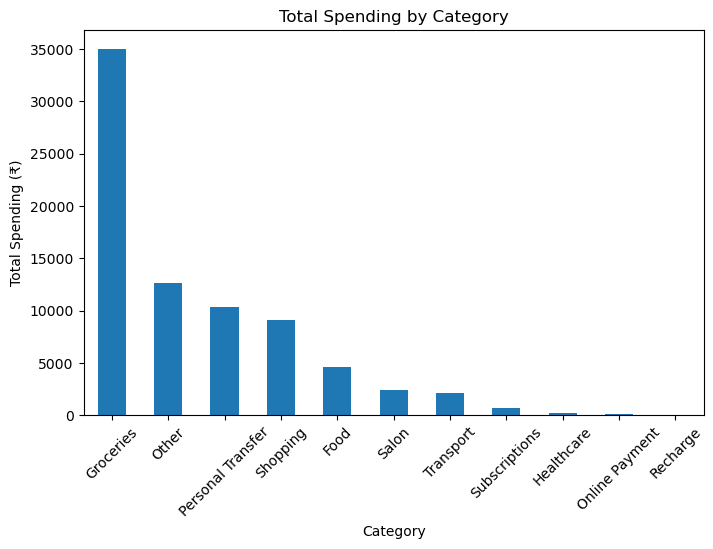

In [61]:
category_spend["Total_Spent"].plot(kind="bar",figsize=(8,5),title="Total Spending by Category")

plt.ylabel("Total Spending (₹)")
plt.xticks(rotation=45)
plt.show()

In [62]:
category_percent=(category_spend["Total_Spent"]/category_spend["Total_Spent"].sum())*100
category_percent.round(2)

Category
Groceries            45.31
Other                16.39
Personal Transfer    13.34
Shopping             11.80
Food                  5.94
Salon                 3.07
Transport             2.79
Subscriptions         0.87
Healthcare            0.30
Online Payment        0.13
Recharge              0.05
Name: Total_Spent, dtype: float64

c. MERCHANT ANALYSIS

In [63]:
top_merchants=(df[df["Transaction_Type"]=="Paid"].groupby("Merchant_Clean")["Amount"].sum().sort_values(ascending=False).head(10))
top_merchants

Merchant_Clean
blinkit                                   19776.55
zepto                                     14883.35
elwin eapen                                5001.00
myntra                                     4829.00
swiggy                                     2722.00
veeralchengappa                            2295.00
ajaiantonyjoseph                           1698.00
nykaa                                      1629.00
karnatakastateroadtransportcorporation     1542.00
greentrends                                1425.90
Name: Amount, dtype: float64

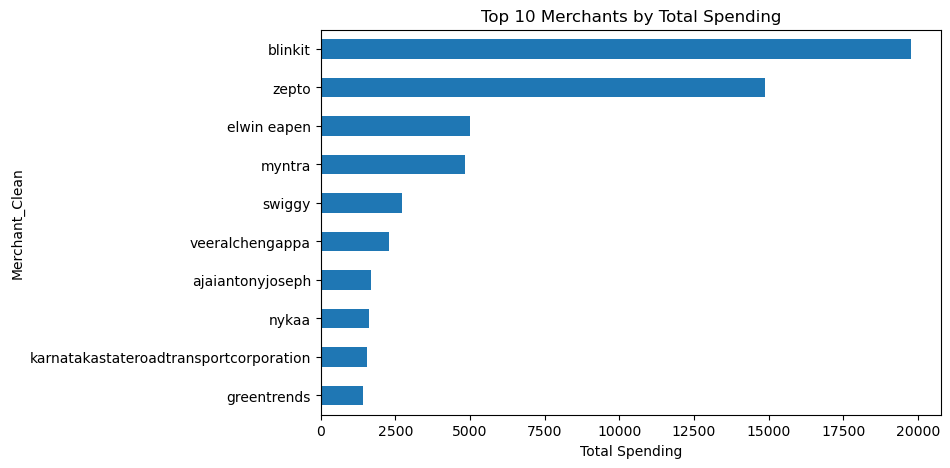

In [64]:
plt.figure(figsize=(8,5))

top_merchants.sort_values().plot(kind="barh")
plt.title("Top 10 Merchants by Total Spending")
plt.xlabel("Total Spending")
plt.show()

d. OTHER TRANSACTIONS

In [65]:
other_merchants=(df[df["Category"]=="Other"].groupby("Merchant_Clean").agg(Transactions=("Amount","size"),Total_Spent=("Amount","sum"),Average_Transaction=("Amount","mean")).sort_values("Transactions",ascending=False))

In [66]:
df[df["Category"]=="Other"][["Date","Merchant","Details","Amount"]].sort_values("Amount").head(200)

,Date,Merchant,Details,Amount
349,2026-04-08,PREPLACEDEDUCATIONPRIVATELIMITED,PaidtoPREPLACEDEDUCATIONPRIVATELIMITED,1.0
271,2026-03-12,RameshMR,PaidtoRameshMR,2.0
136,2026-02-13,RameshMR,PaidtoRameshMR,2.0
389,2026-04-23,RAMESHMR,PaidtoRAMESHMR,2.0
85,2026-01-31,RAMESHMR,PaidtoRAMESHMR,3.0
...,...,...,...,...
206,2026-02-23,HARISHKUMARDR,PaidtoHARISHKUMARDR,240.0
430,2026-05-05,LALRINOMI NGAMLAI,PaidtoLALRINOMI NGAMLAI,250.0
181,2026-02-18,MAHANTHESH R W00616,PaidtoMAHANTHESH R W00616,330.0
197,2026-02-19,Ganesh,PaidtoGanesh,350.0


In [67]:
other_trans=df[df["Category"]=="Other"][["Date","Merchant","Details","Amount"]]
other_trans.sort_values("Merchant")
other_trans.sort_values("Merchant").to_csv("other_transaction_sorted.csv",index=False)

In [68]:
personal_transactions=df[(df["Category"]=="Other")&(df["Merchant"].isin(["AamenaHussain","AfnaazMujawar","AjaiAntonyJoseph","DhillonThimmaiahCB","MRNishanthGowdaCM","FadiAmanSaifudeen","SwastikaSengupta","NamanM","ShereneMariaMathews","Vishal","SameerR","ShivamJPatel"]))][["Date","Merchant","Amount"]]

In [69]:
df.loc[personal_transactions.index, "Category"] = "Personal Transfer"

In [70]:
df["Category"].unique()

array(['Other', 'Personal Transfer', 'Groceries', 'Transport', 'Shopping',
       'Food', 'Salon', 'Healthcare', 'Subscriptions', 'Online Payment',
       'Recharge'], dtype=object)

In [71]:
medical_other = df[
    (df["Category"] == "Other") &
    (df["Merchant"].str.contains("medical|pharmacy|pharma", case=False, na=False))
]

medical_other[["Date", "Merchant", "Amount"]]

,Date,Merchant,Amount


In [72]:
df.loc[medical_other.index, "Category"] = "Healthcare"

In [73]:
df.loc[medical_other.index, "Category"]

Series([], Name: Category, dtype: object)

In [74]:
remaining_other = (
    df[df["Category"] == "Other"]
    .groupby("Merchant")
    .agg(
        Transactions=("Amount", "size"),
        Total_Spent=("Amount", "sum")
    )
    .sort_values("Transactions", ascending=False)
)

remaining_other.head(30)

,Transactions,Total_Spent
Merchant,,
RAMESHMR,11,226.0
RameshMR,8,159.0
BALAJISTATIONERS,3,218.0
RANJANCSSOSHANKAREGOWDAT,3,343.0
SADASHIVA,3,180.0
Ganesh,2,550.0
GOVINDAR,2,135.0
ErannaHm,2,121.0
SUNITHABS,2,165.0


In [75]:
df[
    (df["Category"] == "Other") &
    (df["Merchant"].str.contains("CONDIMENT", case=False, na=False))
][["Date", "Merchant", "Details", "Amount"]]

,Date,Merchant,Details,Amount
291,2026-03-17,NAVEEDCONDIMENTS,PaidtoNAVEEDCONDIMENTS,48.0


In [76]:
df.loc[(df["Category"]=="Other")&(df["Merchant"].str.contains("CONDIMENT",case=False, na=False)),"Category"]="Groceries"

In [77]:
df.loc[291, ["Merchant", "Amount", "Category"]]

Merchant    NAVEEDCONDIMENTS
Amount                  48.0
Category           Groceries
Name: 291, dtype: object

In [78]:
other_summary = (
    df["Category"]
    .value_counts()
    .to_frame("Transactions")
)

other_summary["Percentage"] = (
    other_summary["Transactions"] / len(df) * 100
).round(2)

other_summary

,Transactions,Percentage
Other,184,35.87
Personal Transfer,177,34.50
Groceries,75,14.62
Food,25,4.87
Shopping,19,3.70
Transport,14,2.73
Salon,6,1.17
Subscriptions,5,0.97
Healthcare,3,0.58
Online Payment,3,0.58


In [79]:
df[df["Category"] == "Other"]["Amount"].describe()

count    184.000000
mean      69.983859
std       76.123766
min        1.000000
25%       46.862500
50%       56.000000
75%       70.000000
max      820.000000
Name: Amount, dtype: float64

In [80]:
other_above_100 = df[
    (df["Category"] == "Other") &
    (df["Amount"] > 100)
][["Date", "Merchant", "Details", "Amount"]]

other_above_100.sort_values("Amount", ascending=False)

,Date,Merchant,Details,Amount
199,2026-02-19,SakaleshKg,PaidtoSakaleshKg,820.0
197,2026-02-19,Ganesh,PaidtoGanesh,350.0
181,2026-02-18,MAHANTHESH R W00616,PaidtoMAHANTHESH R W00616,330.0
430,2026-05-05,LALRINOMI NGAMLAI,PaidtoLALRINOMI NGAMLAI,250.0
206,2026-02-23,HARISHKUMARDR,PaidtoHARISHKUMARDR,240.0
176,2026-02-18,FAISALNOWSHAD,PaidtoFAISALNOWSHAD,240.0
1,2026-01-03,SHIVANNA SHIVANNA,PaidtoSHIVANNA SHIVANNA,231.0
195,2026-02-19,Ganesh,PaidtoGanesh,200.0
14,2026-01-10,SUDHAKAR CHITIKELA,PaidtoSUDHAKAR CHITIKELA,173.0
216,2026-02-24,PRASHANTHPRASHANTH,PaidtoPRASHANTHPRASHANTH,173.0


In [81]:
other_summary = (
    df["Category"]
    .value_counts()
    .to_frame("Transactions")
)

other_summary["Percentage"] = (
    other_summary["Transactions"] / len(df) * 100
).round(2)

other_summary

,Transactions,Percentage
Other,184,35.87
Personal Transfer,177,34.50
Groceries,75,14.62
Food,25,4.87
Shopping,19,3.70
Transport,14,2.73
Salon,6,1.17
Subscriptions,5,0.97
Healthcare,3,0.58
Online Payment,3,0.58


In [82]:
remaining_other = df[df["Category"] == "Other"][
    ["Date", "Merchant", "Details", "Amount"]
].sort_values("Date")

remaining_other.to_csv(
    "remaining_other_transactions.csv",
    index=False
)

In [83]:
other_spending = df[df["Category"] == "Other"]["Amount"].sum()

total_spending = df[df["Transaction_Type"] == "Paid"]["Amount"].sum()

print("Other spending: ₹", round(other_spending, 2))
print("Other spending %:", round(other_spending / total_spending * 100, 2))

Other spending: ₹ 12877.03
Other spending %: 16.64


In [84]:
other_uber_range = df[
    (df["Category"] == "Other") &
    (df["Amount"].between(47, 80))
]

print("Transactions:", len(other_uber_range))
print("Total spent: ₹", round(other_uber_range["Amount"].sum(), 2))
print("Share of Other transactions:",
      round(len(other_uber_range) / len(df[df["Category"] == "Other"]) * 100, 2))
print("Share of Other spending:",
      round(other_uber_range["Amount"].sum() /
            df[df["Category"] == "Other"]["Amount"].sum() * 100, 2))

Transactions: 105
Total spent: ₹ 6190.58
Share of Other transactions: 57.07
Share of Other spending: 48.07


In [85]:
other_ride_range = df[
    (df["Category"] == "Other") &
    (df["Amount"].between(47, 80))
].copy()

other_ride_range[["Date", "Time", "Merchant", "Amount"]].head(20)

,Date,Time,Merchant,Amount
2,2026-01-05,1900-01-01 07:29:00,PARASHURAMA,56.15
19,2026-01-12,1900-01-01 07:27:00,GOVINDAR,68.00
21,2026-01-12,1900-01-01 09:46:00,SADASHIVA,60.00
24,2026-01-14,1900-01-01 07:49:00,RANJANCSSOSHANKAREGOWDAT,66.00
33,2026-01-16,1900-01-01 08:11:00,RIDAFATHIMAKHANUM,62.00
46,2026-01-22,1900-01-01 08:12:00,Saniya Sultana,56.00
62,2026-01-28,1900-01-01 10:27:00,MRCHENNEGOWDA KC,59.00
71,2026-01-29,1900-01-01 08:00:00,KISHANKUMAR,56.00
77,2026-01-30,1900-01-01 08:01:00,ErannaHm,56.00
86,2026-01-31,1900-01-01 14:05:00,VENKATESHG,70.00


A substantial proportion of otherwise uncategorised transactions occurred within the ₹47–₹80 range, consistent with the user's typical ride-hailing expenditure. However, these transactions were retained under Other because the available merchant information did not reliably identify them as transport expenses.

In [86]:
len(df)

513

In [87]:
df["Transaction_Type"].value_counts()

Paid        370
Received    143
Name: Transaction_Type, dtype: int64

In [88]:
df.duplicated().sum()

0

In [89]:
df.groupby("Month").size()

Month
April        86
February    151
January      87
June         21
March        85
May          83
dtype: int64

In [90]:
likely_transport=df[(df["Category"]=="Other")&(df["Merchant"].str.match(r"KA\d{2}",na=False))]
likely_transport

,Date,Time,Details,Amount,UPI_ID,Bank,Transaction_Type,Merchant,Merchant_Clean,Month,Month_Num,Day,Year,Day_Type,Hour,Category
9,2026-01-08,1900-01-01 11:38:00,PaidtoKA01AR2969,15.0,600812237069,PaidbyStateBankofIndia7202,Paid,KA01AR2969,ka01ar2969,January,1,Thursday,2026,Weekday,11,Other
26,2026-01-14,1900-01-01 11:07:00,PaidtoKA01AR2872,15.0,601418439014,PaidbyStateBankofIndia7202,Paid,KA01AR2872,ka01ar2872,January,1,Wednesday,2026,Weekday,11,Other
34,2026-01-16,1900-01-01 13:28:00,PaidtoKA01AR1160,15.0,601653745605,PaidbyStateBankofIndia7202,Paid,KA01AR1160,ka01ar1160,January,1,Friday,2026,Weekday,13,Other
79,2026-01-30,1900-01-01 12:50:00,PaidtoKA51AL6812,6.0,603096414572,PaidbyStateBankofIndia7202,Paid,KA51AL6812,ka51al6812,January,1,Friday,2026,Weekday,12,Other
118,2026-02-07,1900-01-01 13:33:00,PaidtoKA01AR1160,15.0,603861454077,PaidbyStateBankofIndia7202,Paid,KA01AR1160,ka01ar1160,February,2,Saturday,2026,Weekend,13,Other
303,2026-03-23,1900-01-01 12:41:00,PaidtoKA01AR4375,15.0,608209573794,PaidbyStateBankofIndia7202,Paid,KA01AR4375,ka01ar4375,March,3,Monday,2026,Weekday,12,Other
311,2026-03-26,1900-01-01 11:17:00,PaidtoKA01AR2824,15.0,608584665222,PaidbyStateBankofIndia7202,Paid,KA01AR2824,ka01ar2824,March,3,Thursday,2026,Weekday,11,Other
315,2026-03-27,1900-01-01 12:56:00,PaidtoKA01AR4375,15.0,608656230726,PaidbyStateBankofIndia7202,Paid,KA01AR4375,ka01ar4375,March,3,Friday,2026,Weekday,12,Other
439,2026-05-07,1900-01-01 15:34:00,PaidtoKA01AR2809,15.0,612775442856,PaidbyStateBankofIndia7202,Paid,KA01AR2809,ka01ar2809,May,5,Thursday,2026,Weekday,15,Other


In [91]:
len(likely_transport)

9

In [92]:
likely_transport["Amount"].sum()
likely_transport["Amount"].describe()

count     9.0
mean     14.0
std       3.0
min       6.0
25%      15.0
50%      15.0
75%      15.0
max      15.0
Name: Amount, dtype: float64

In [93]:
df.loc[likely_transport.index,"Category"]="Transport"

In [94]:
df.loc[likely_transport.index,"Category"]

9      Transport
26     Transport
34     Transport
79     Transport
118    Transport
303    Transport
311    Transport
315    Transport
439    Transport
Name: Category, dtype: object

7. MONTHLY SPENDING TREND

In [ ]:
monthly_spending=df[df["Transaction_Type"]=="Paid"].groupby("Month")["Amount"].sum()
month_order=["January","February","March","April","May","June"]
monthly_spending= monthly_spending.reindex(month_order)
monthly_spending

Month
January     14027.44
February    22120.71
March       10446.02
April        7140.82
May         13462.00
June        10172.00
Name: Amount, dtype: float64

In [96]:
monthly_spending.round(2)

Month
January     14027.44
February    22120.71
March       10446.02
April        7140.82
May         13462.00
June        10172.00
Name: Amount, dtype: float64

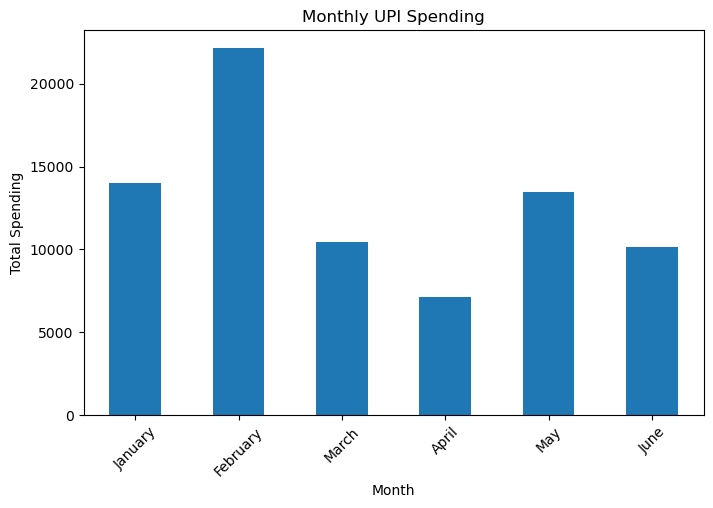

In [97]:
monthly_spending.plot(kind="bar",figsize=(8,5),title="Monthly UPI Spending")
plt.xlabel("Month")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.show()

In [98]:
highest_month=monthly_spending.idxmax()
highest_amount=monthly_spending.max()
lowest_month=monthly_spending.idxmin()
lowest_amount=monthly_spending.min()
print(f"Highest Spending: {highest_month}= ₹{highest_amount}")
print(f"Lowest Spending: {lowest_month}= ₹{lowest_amount}")

Highest Spending: February= ₹22120.71
Lowest Spending: April= ₹7140.82


8. TRANSACTION BEHAVIOUR

In [99]:
transactions_by_month = (
    df[df["Transaction_Type"] == "Paid"]
    .groupby("Month")
    .size()
)

transactions_by_month

Month
April        61
February    107
January      61
June         14
March        68
May          59
dtype: int64

In [100]:
transactions_by_month = transactions_by_month.reindex(month_order)

transactions_by_month

Month
January      61
February    107
March        68
April        61
May          59
June         14
dtype: int64

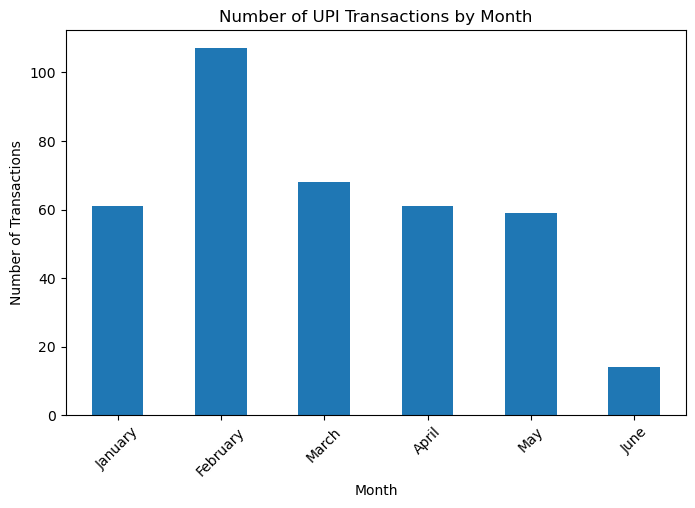

In [101]:
transactions_by_month.plot(kind="bar",figsize=(8,5),title="Number of UPI Transactions by Month"
)

plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.show()

In [102]:
average_transaction = (
    df[df["Transaction_Type"] == "Paid"]
    .groupby("Month")["Amount"]
    .mean()
)

average_transaction = average_transaction.reindex(month_order)
average_transaction.round(2)

Month
January     229.96
February    206.74
March       153.62
April       117.06
May         228.17
June        726.57
Name: Amount, dtype: float64

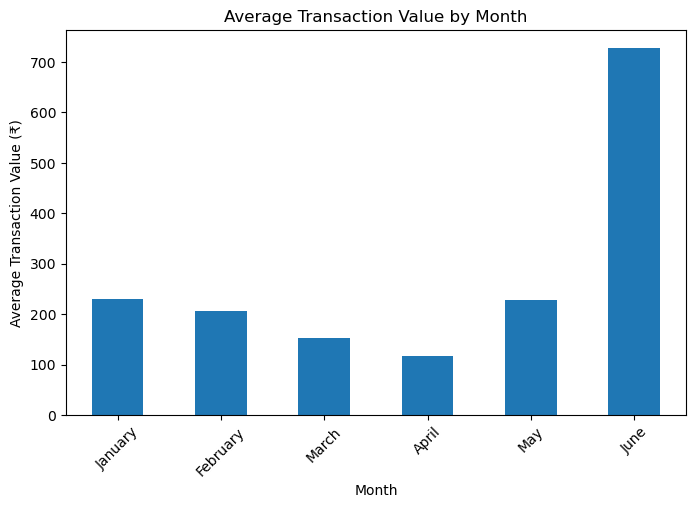

In [103]:
average_transaction.plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Transaction Value by Month"
)

plt.xlabel("Month")
plt.ylabel("Average Transaction Value (₹)")
plt.xticks(rotation=45)
plt.show()

In [104]:
weekday_weekend = (
    df[df["Transaction_Type"] == "Paid"]
    .groupby("Day_Type")["Amount"]
    .sum()
)

weekday_weekend

Day_Type
Weekday    60123.92
Weekend    17245.07
Name: Amount, dtype: float64

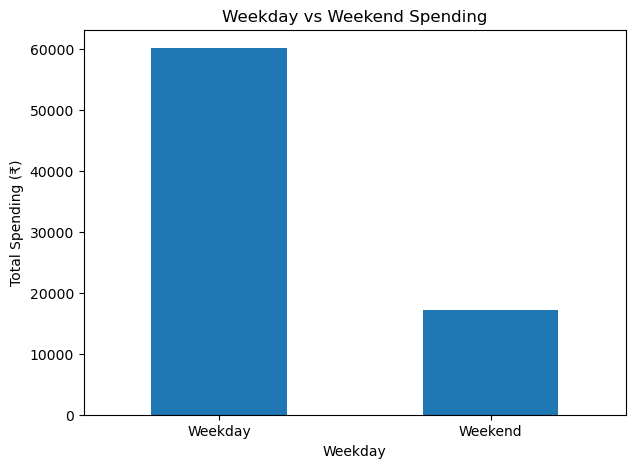

In [105]:
weekday_weekend.plot(
    kind="bar",
    figsize=(7, 5),
    title="Weekday vs Weekend Spending"
)

plt.xlabel("Weekday")
plt.ylabel("Total Spending (₹)")
plt.xticks(rotation=0)
plt.show()

In [106]:
largest_payments = (
    df[df["Transaction_Type"] == "Paid"]
    .nlargest(10, "Amount")
    [["Date", "Merchant", "Category", "Amount"]]
)

largest_payments

,Date,Merchant,Category,Amount
505,2026-06-18,Myntra,Shopping,2277.0
445,2026-05-08,ELWINEAPEN,Personal Transfer,2044.0
488,2026-05-27,Blinkit,Groceries,1819.0
510,2026-06-25,Myntra,Shopping,1739.0
145,2026-02-14,NYKAA,Shopping,1629.0
191,2026-02-19,KARNATAKASTATEROADTRANSPORTCORPORATION,Transport,1542.0
56,2026-01-26,ZEPTOMARKETPLACEPRIVATELIMITED,Groceries,1524.0
464,2026-05-12,AjaiAntonyJoseph,Personal Transfer,1500.0
44,2026-01-21,Blinkit,Groceries,1304.0
18,2026-01-11,ElwinEapenM,Personal Transfer,1300.0


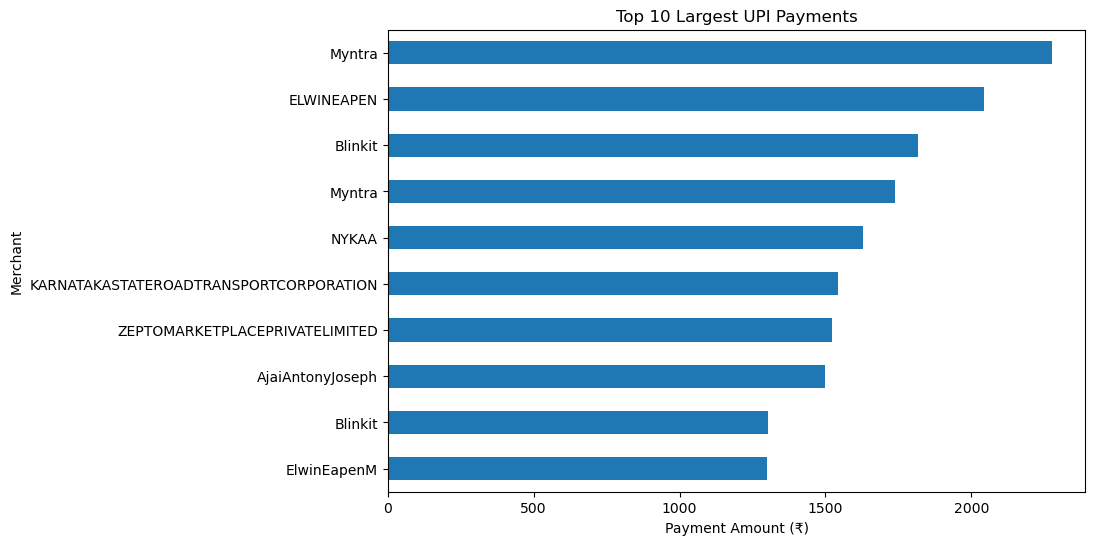

In [107]:
largest_payments_sorted = largest_payments.sort_values("Amount")

largest_payments_sorted.plot(
    x="Merchant",
    y="Amount",
    kind="barh",
    figsize=(9, 6),
    title="Top 10 Largest UPI Payments",
    legend=False
)

plt.xlabel("Payment Amount (₹)")
plt.ylabel("Merchant")
plt.show()

In [108]:
paid = df[df["Transaction_Type"]=="Paid"].copy()

paid_sorted = paid.sort_values("Amount", ascending=False)

top_10_percent_count = int(len(paid_sorted) * 0.10)

top_10_percent_spending = paid_sorted.head(top_10_percent_count)["Amount"].sum()

total_spending = paid_sorted["Amount"].sum()

print("Top 10% transaction count:", top_10_percent_count)
print("Top 10% spending: ₹", round(top_10_percent_spending, 2))
print(
    "Share of total spending:",
    round(top_10_percent_spending / total_spending * 100, 2),
    "%"
)

Top 10% transaction count: 37
Top 10% spending: ₹ 39955.07
Share of total spending: 51.64 %


In [109]:
top_10_percent = paid_sorted.head(top_10_percent_count)

top_10_percent[
    ["Date", "Merchant", "Category", "Amount"]
]

,Date,Merchant,Category,Amount
505,2026-06-18,Myntra,Shopping,2277.00
445,2026-05-08,ELWINEAPEN,Personal Transfer,2044.00
488,2026-05-27,Blinkit,Groceries,1819.00
510,2026-06-25,Myntra,Shopping,1739.00
145,2026-02-14,NYKAA,Shopping,1629.00
191,2026-02-19,KARNATAKASTATEROADTRANSPORTCORPORATION,Transport,1542.00
56,2026-01-26,ZEPTOMARKETPLACEPRIVATELIMITED,Groceries,1524.00
464,2026-05-12,AjaiAntonyJoseph,Personal Transfer,1500.00
44,2026-01-21,Blinkit,Groceries,1304.00
18,2026-01-11,ElwinEapenM,Personal Transfer,1300.00


In [110]:
top10_category = (
    top_10_percent
    .groupby("Category")["Amount"]
    .agg(["count", "sum"])
    .sort_values("sum", ascending=False)
)

top10_category

,count,sum
Category,,
Groceries,21,20632.07
Personal Transfer,6,7644.00
Shopping,5,7413.00
Transport,1,1542.00
Salon,2,1288.00
Other,1,820.00
Food,1,616.00


SPENDING CONCENTRATION
- The largest 10% of paid transactions (37 transactions) accounted for 51.64% of total spending. 
- Groceries were the largest contributor, accounting for 21 of these transactions and ₹20,632.07 (51.7%) of their combined value.
- Groceries, shopping and personal transfers together represented approximately 90.8% of spending within the top 10% of transactions.

9. KEY INSIGHTS

- Groceries were the largest spending category, accounting for 45.37% of total spending. This suggests that routine grocery purchases were the primary contributor to overall expenditure.

- Spending was relatively concentated among a small number of large transactions. The top 10% of transactions accounted for 51.7% of total spending, indicating that a relatively small number of high- value transactions had a disproportionate impact on total expenditure.

- Personal transfers represented 13.34% of total spending, making them the second largest category by spending share after groceries. This highlights the imprtance of seperating transfers from actual consumption where analysing personal spending behavior.

- Shopping accounted for 12.34% of spending, with major merchants such as Myntra, Nykaa and Ajio contributing to this category.

- Food accounted for 5.94% of spending, while transport accounted for 2.95% and salon expenses 3.07%. These categories represent smaller but recurring components of discretionary spending.

- Merchant-name normalisation significantly improved the analysis. Variations such as different spellings, casing and legal entity names were consolidated into consistent merchant names, making merchant-level frequency and category analysis more reliable.

- The analysis identified a meaningful "Other" category of 15.34%. These transactions were retained rather than arbitrarily classified when the merchant information was insufficient to confidently determine their category. 

10. LIMITATIONS

- Limited dataset size and time period: The analysis is based on a relatively small personal transaction dataset covering a limited period, so the patterns observed may not generalise to longer-term spending behaviour.

- Manual category mapping: Although merchant names were normalised using string matching and regex, some transactions required manual classification. This introduces the possibility of subjective categorisation.

- Ambiguous merchant descriptions: Some UPI transactions do not provide sufficiently descriptive merchant information. These were retained under Other, which limits the granularity of category-level insights.

- Personal transfers can distort spending analysis: Transfers between individuals may represent money movement rather than actual consumption. Therefore, total transaction value should not automatically be interpreted as total personal consumption.

- No income or budget context: The dataset focuses on transactions and does not contain corresponding income, savings targets or budgets. Therefore, the project can identify spending patterns but cannot assess affordability, financial health or whether spending levels are appropriate.